### Uses X_train.csv and X_test.csv (unscaled, trees don't need scaling)
### Uses class_weight = "balanced" (sample weights for boosting) to battle class imbalance
### Uses PR-AUC tuning since accuracy is useless
### 5-fold cross validation on train, threshold picked from CV
### Test set touched once at the very end
### One tuned model each: Bagging, Random Forest, AdaBoost, Gradient Boosting, Stacking
### Each model section makes one slide: metrics (train / CV / test), confusion matrix, ROC, tuning, over/underfitting check

In [1]:
from pathlib import Path
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, train_test_split

os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
QUICK = False  # True = 8,000 training rows + small grids, just to check everything runs
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

#finds data/processed from models/, the repo root, or the D: drive clone
def find_data_dir():
    here = Path.cwd().resolve()
    candidates = [p / "data" / "processed" for p in [here, *here.parents]]
    candidates.append(Path(r"D:\GitHub\Forecasting_Commercial_Success_of_a_SteamGame_using_MachineLearning\data\processed"))
    for c in candidates:
        if (c / "X_train.csv").exists():
            return c
    raise FileNotFoundError("Could not find data/processed/X_train.csv, run preprocessing.ipynb first")

DATA_DIR = find_data_dir()

### Loading unscaled data and making sure everything matches up

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["hit"]
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["hit"]
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
if QUICK:
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)
    X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
print(f"Train {X_train.shape}, Test {X_test.shape}")
print(f"Hit rate: Train {y_train.mean():.1%}, Test {y_test.mean():.1%} (imbalance ratio in train {(y_train == 0).sum() / (y_train == 1).sum():.1f}:1)")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sample_w = compute_sample_weight("balanced", y_train)  #boosting has no class_weight, so balanced sample weights instead

Train (45491, 25), Test (21760, 25)
Hit rate: Train 10.9%, Test 5.6% (imbalance ratio in train 8.2:1)


### Helper functions

In [3]:
#finds the threshold with the highest F1 on these predictions
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2*prec*rec/np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return f1[i], thr[i]

def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)}

#best train vs validation score for each value of one hyperparameter (other settings at their best)
def tuning_curve(search, param):
    cv = pd.DataFrame(search.cv_results_)
    col = f"param_{param}"
    cv[col] = cv["params"].apply(lambda d: str(d[param]))  #str() keeps None as "None"
    best_rows = cv.loc[cv.groupby(col)["mean_test_score"].idxmax()].set_index(col)
    order = [str(v) for v in search.param_grid[param]]  #keep the grid's order on the x-axis
    best_rows = best_rows.loc[order]
    return order, best_rows["mean_train_score"].to_numpy(), best_rows["mean_test_score"].to_numpy()

results = {}  #test scores + probabilities for every model, used in the comparison at the end

#everything one slide needs: tuning summary, metrics on train / CV / test, confusion matrix, ROC, PR, overfitting check
def model_slide(name, search, param, Xtr=X_train, Xte=X_test, use_weights=False):
    best = search.best_estimator_
    fit_params = {"sample_weight": sample_w} if use_weights else None

    #threshold from 5-fold CV on train (test is never used to pick anything)
    oof = cross_val_predict(clone(best), Xtr, y_train, cv=skf, method="predict_proba", n_jobs=-1, params=fit_params)[:, 1]
    _, thr = best_f1_threshold(y_train, oof)
    p_train = best.predict_proba(Xtr)[:, 1]
    p_test = best.predict_proba(Xte)[:, 1]

    print(f"===== {name} =====")
    print("Grid searched:", search.param_grid)
    print("Best parameters:", search.best_params_)
    print(f"Threshold (CV F1-optimal): {thr:.3f}")
    table = pd.DataFrame({"Train": metrics(y_train, p_train, thr), "5-fold CV": metrics(y_train, oof, thr),
                          "Test": metrics(y_test, p_test, thr)}).T
    display(table.round(3))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= thr).astype(int)), display_labels=["not hit", "hit"]).plot(ax=axes[0], colorbar=False, cmap="Blues", values_format="d")
    axes[0].set_title(f"Test confusion matrix (threshold {thr:.2f})")
    axes[0].grid(False)

    for y, p, label, style in [(y_train, p_train, "Train", ":"), (y_train, oof, "5-fold CV", "--"), (y_test, p_test, "Test", "-")]:
        fpr, tpr, _ = roc_curve(y, p)
        axes[1].plot(fpr, tpr, ls=style, label=f"{label} (AUC {roc_auc_score(y, p):.3f})")
    axes[1].plot([0, 1], [0, 1], color="gray", lw=0.8)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    axes[1].legend(fontsize=8)

    prec, rec, _ = precision_recall_curve(y_test, p_test)
    axes[2].plot(rec, prec, color="blue", label=f"Test (PR-AUC {average_precision_score(y_test, p_test):.3f})")
    axes[2].axhline(y_test.mean(), color="gray", ls="--", label="random guesser")
    axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve (test)")
    axes[2].legend(fontsize=8)

    values, tr, va = tuning_curve(search, param)
    axes[3].plot(values, tr, marker="o", color="red", label="Train folds")
    axes[3].plot(values, va, marker="o", color="blue", label="Validation folds")
    axes[3].set(xlabel=param.replace("estimator__", ""), ylabel="PR-AUC", title="Tuning + overfitting check")
    axes[3].legend(fontsize=8)
    fig.suptitle(name, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

    results[name] = {**metrics(y_test, p_test, thr), "threshold": thr, "p_test": p_test,
                     "CV PR-AUC": average_precision_score(y_train, oof), "train-CV gap": average_precision_score(y_train, p_train) - average_precision_score(y_train, oof)}
    return best, oof, p_test

## Bagging
Many decision trees, each trained on a bootstrap sample (rows drawn with replacement), predictions averaged. Deep trees overfit their own sample in different ways, so averaging reduces variance.

Grid search took 491s
===== Bagging =====
Grid searched: {'n_estimators': [50, 100, 200], 'max_samples': [0.5, 0.8, 1.0], 'estimator__min_samples_leaf': [1, 5, 20, 50]}
Best parameters: {'estimator__min_samples_leaf': 20, 'max_samples': 0.5, 'n_estimators': 200}
Threshold (CV F1-optimal): 0.672


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
Train,0.905,0.566,0.570,0.568,0.625,0.914
5-fold CV,0.896,0.522,0.520,0.521,0.533,0.846
Test,0.913,0.339,0.569,0.425,0.427,0.850


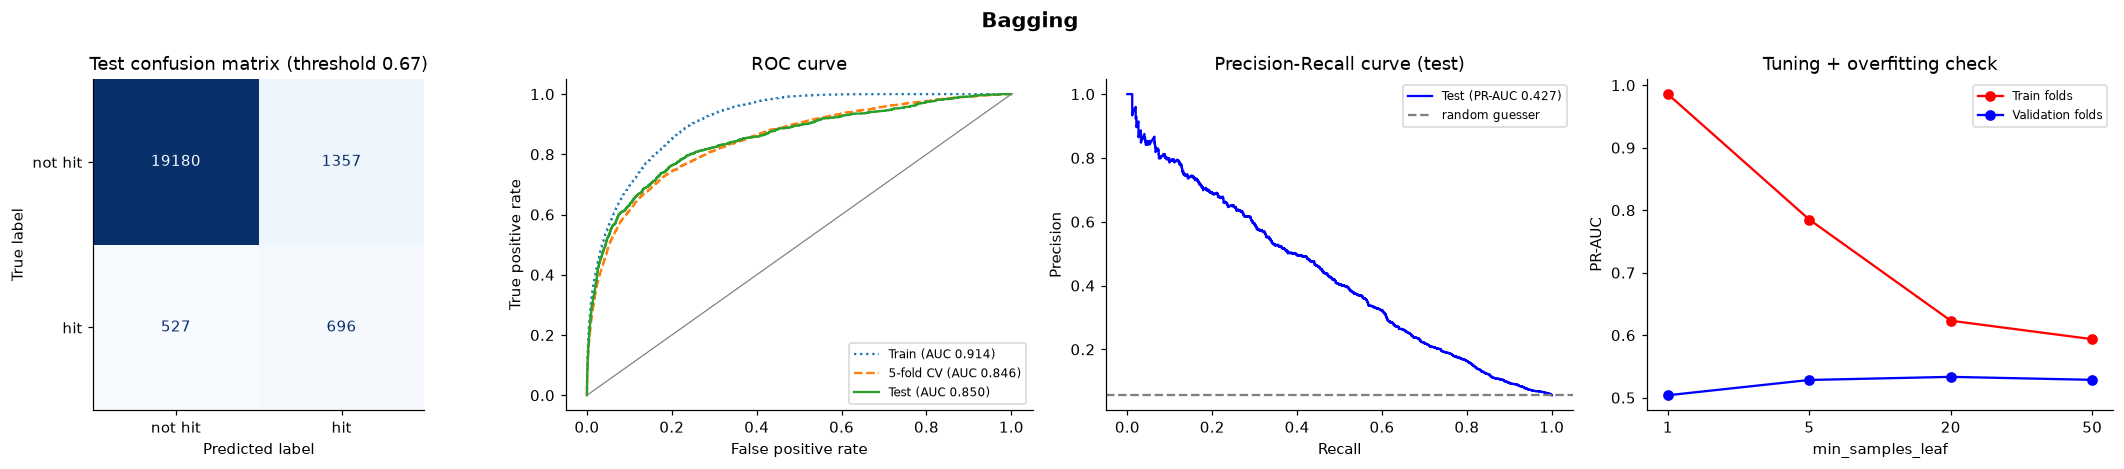

In [4]:
t0 = time.time()
bag_grid = GridSearchCV(
    BaggingClassifier(estimator=DecisionTreeClassifier(class_weight="balanced"), bootstrap=True, random_state=RANDOM_STATE),
    {"n_estimators": [100] if QUICK else [50, 100, 200],
     "max_samples": [0.5, 0.8] if QUICK else [0.5, 0.8, 1.0],
     "estimator__min_samples_leaf": [1, 10] if QUICK else [1, 5, 20, 50]},
    scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
bag_grid.fit(X_train, y_train)
print(f"Grid search took {time.time() - t0:.0f}s")
bag_best, bag_oof, _ = model_slide("Bagging", bag_grid, "estimator__min_samples_leaf")

Small leaves = each tree memorizes its sample (train score near 1.0, big gap to validation). Bigger leaves trade a bit of train score for a smaller gap.

## Random Forest
Bagging with trees, but each split only looks at a random subset of features. The trees end up less alike, so averaging cancels out more of their errors.

Grid search took 256s
===== Random Forest =====
Grid searched: {'max_depth': [6, 10, 16, None], 'min_samples_leaf': [1, 5, 20], 'max_features': ['sqrt', 0.5]}
Best parameters: {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 5}
Threshold (CV F1-optimal): 0.659


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
Train,0.926,0.646,0.703,0.673,0.754,0.926
5-fold CV,0.895,0.519,0.536,0.528,0.545,0.852
Test,0.912,0.339,0.590,0.431,0.437,0.852


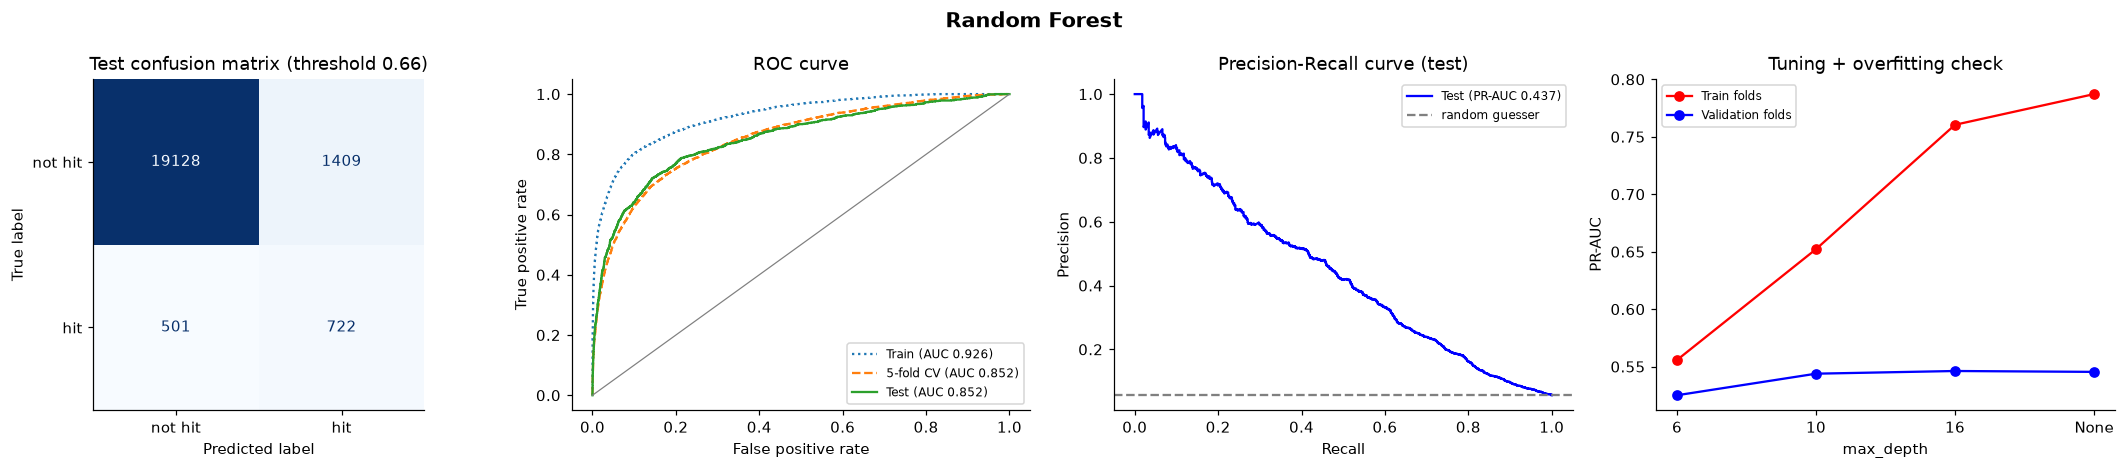

In [5]:
t0 = time.time()
rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=100 if QUICK else 300, class_weight="balanced", random_state=RANDOM_STATE),
    {"max_depth": [6, None] if QUICK else [6, 10, 16, None],
     "min_samples_leaf": [1, 10] if QUICK else [1, 5, 20],
     "max_features": ["sqrt"] if QUICK else ["sqrt", 0.5]},
    scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
rf_grid.fit(X_train, y_train)
print(f"Grid search took {time.time() - t0:.0f}s")
rf_best, rf_oof, _ = model_slide("Random Forest", rf_grid, "max_depth")

Shallow trees underfit (train and validation both low), unlimited depth pushes the train score toward 1.0 while validation levels off.

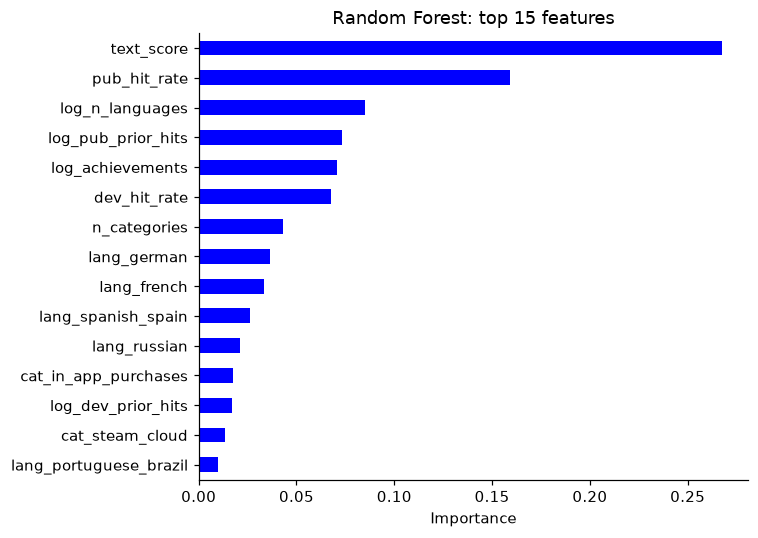

In [6]:
imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.tail(15).plot.barh(ax=ax, color="blue")
ax.set_title("Random Forest: top 15 features")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## AdaBoost
Weak trees trained one after another. After every round the misclassified rows get more weight so the next tree focuses on them, and more accurate trees get a bigger vote. Reduces bias.

Grid search took 160s
===== AdaBoost =====
Grid searched: {'n_estimators': [100, 300], 'learning_rate': [0.1, 0.5, 1.0], 'estimator__max_depth': [1, 2, 3]}
Best parameters: {'estimator__max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 300}
Threshold (CV F1-optimal): 0.621


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
Train,0.890,0.495,0.568,0.529,0.556,0.855
5-fold CV,0.888,0.488,0.564,0.523,0.544,0.850
Test,0.903,0.313,0.609,0.414,0.437,0.854


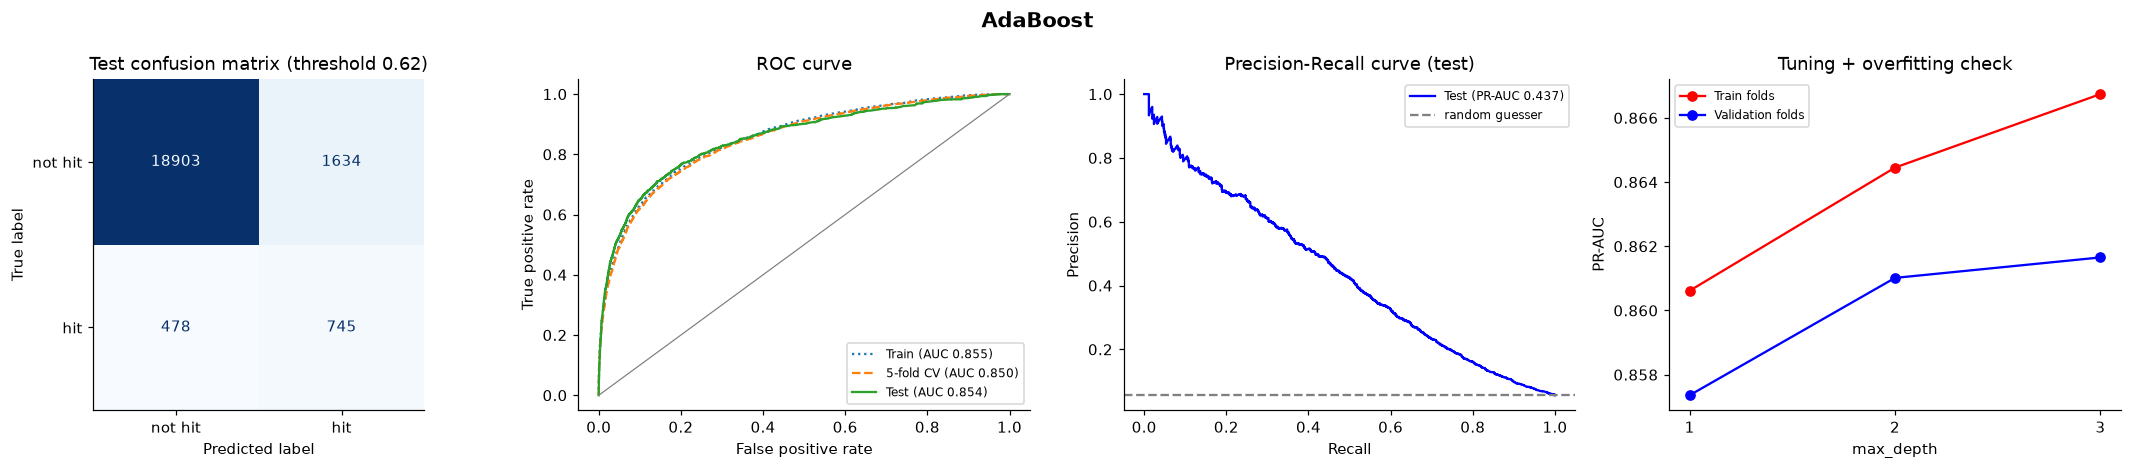

In [7]:
t0 = time.time()
ada_grid = GridSearchCV(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=RANDOM_STATE),
    {"n_estimators": [100] if QUICK else [100, 300],
     "learning_rate": [0.5, 1.0] if QUICK else [0.1, 0.5, 1.0],
     "estimator__max_depth": [1, 2] if QUICK else [1, 2, 3]},
    scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
ada_grid.fit(X_train, y_train, sample_weight=sample_w)
print(f"Grid search took {time.time() - t0:.0f}s")
ada_best, ada_oof, _ = model_slide("AdaBoost", ada_grid, "estimator__max_depth", use_weights=True)

## Gradient Boosting
Also trains trees one after another, but each new tree is fit to the remaining errors (residuals) of the trees so far. The learning rate controls how much each tree adds.

Grid search took 145s
===== Gradient Boosting =====
Grid searched: {'n_estimators': [150, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, 4, 5]}
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
Threshold (CV F1-optimal): 0.736


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
Train,0.898,0.531,0.570,0.550,0.583,0.870
5-fold CV,0.894,0.514,0.553,0.533,0.555,0.854
Test,0.910,0.332,0.588,0.425,0.435,0.855


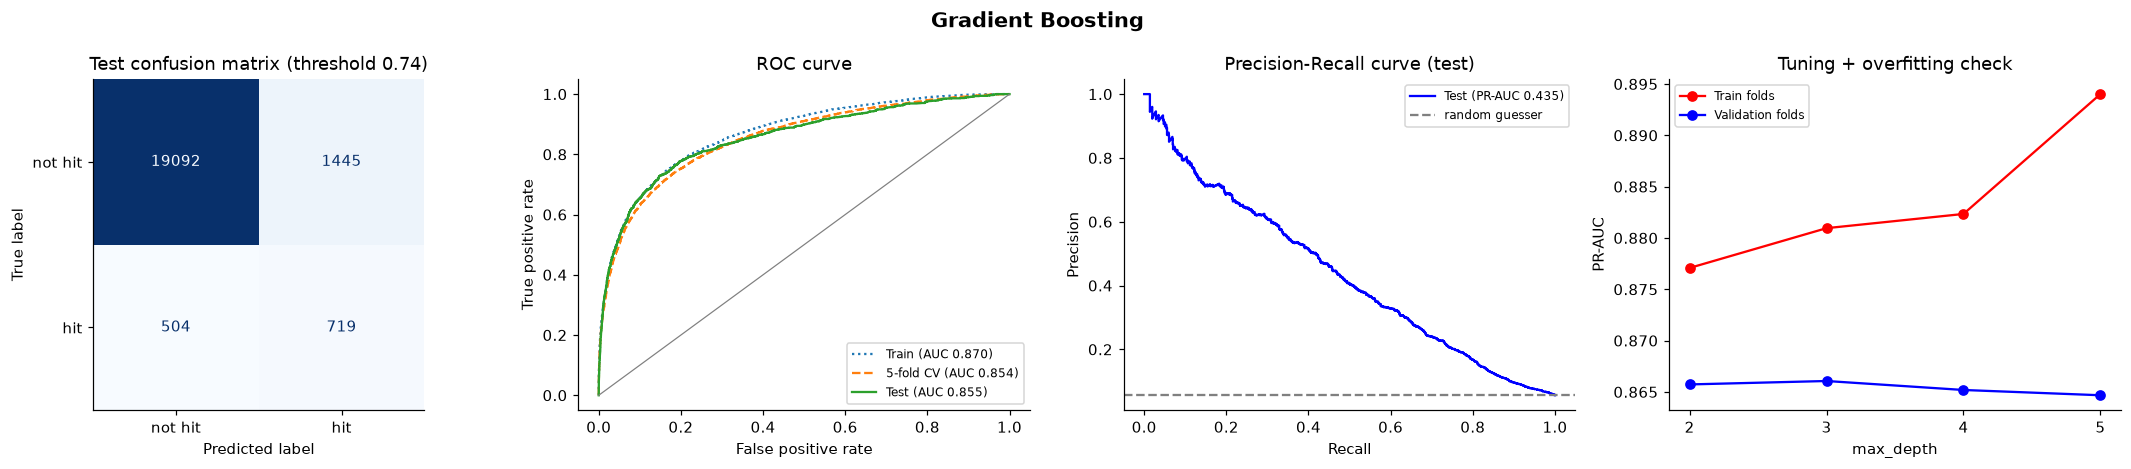

In [8]:
t0 = time.time()
gb_grid = GridSearchCV(
    GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE),
    {"n_estimators": [100] if QUICK else [150, 300],
     "learning_rate": [0.1] if QUICK else [0.05, 0.1],
     "max_depth": [2, 3] if QUICK else [2, 3, 4, 5]},
    scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
gb_grid.fit(X_train, y_train, sample_weight=sample_w)
print(f"Grid search took {time.time() - t0:.0f}s")
gb_best, gb_oof, _ = model_slide("Gradient Boosting", gb_grid, "max_depth", use_weights=True)

## Stacking
1. Each base model (Random Forest, AdaBoost, Gradient Boosting + logistic regression) makes out-of-fold predictions on train with 5-fold CV
2. Those predictions become the features of a new dataset
3. A logistic regression (the meta-learner) is trained on it and learns how much to trust each base model

Works best when the base models make different mistakes.

How similar are the base models' predictions? (correlation)


,Random Forest,AdaBoost,Gradient Boosting,Logistic Regression
Random Forest,1.000,0.945,0.959,0.904
AdaBoost,0.945,1.000,0.971,0.943
Gradient Boosting,0.959,0.971,1.000,0.931
Logistic Regression,0.904,0.943,0.931,1.000


===== Stacking =====
Grid searched: {'C': [0.001, 0.01, 0.1, 1, 10]}
Best parameters: {'C': 0.1}
Threshold (CV F1-optimal): 0.755


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
Train,0.899,0.536,0.532,0.534,0.557,0.855
5-fold CV,0.899,0.535,0.533,0.534,0.556,0.855
Test,0.917,0.352,0.575,0.437,0.453,0.857


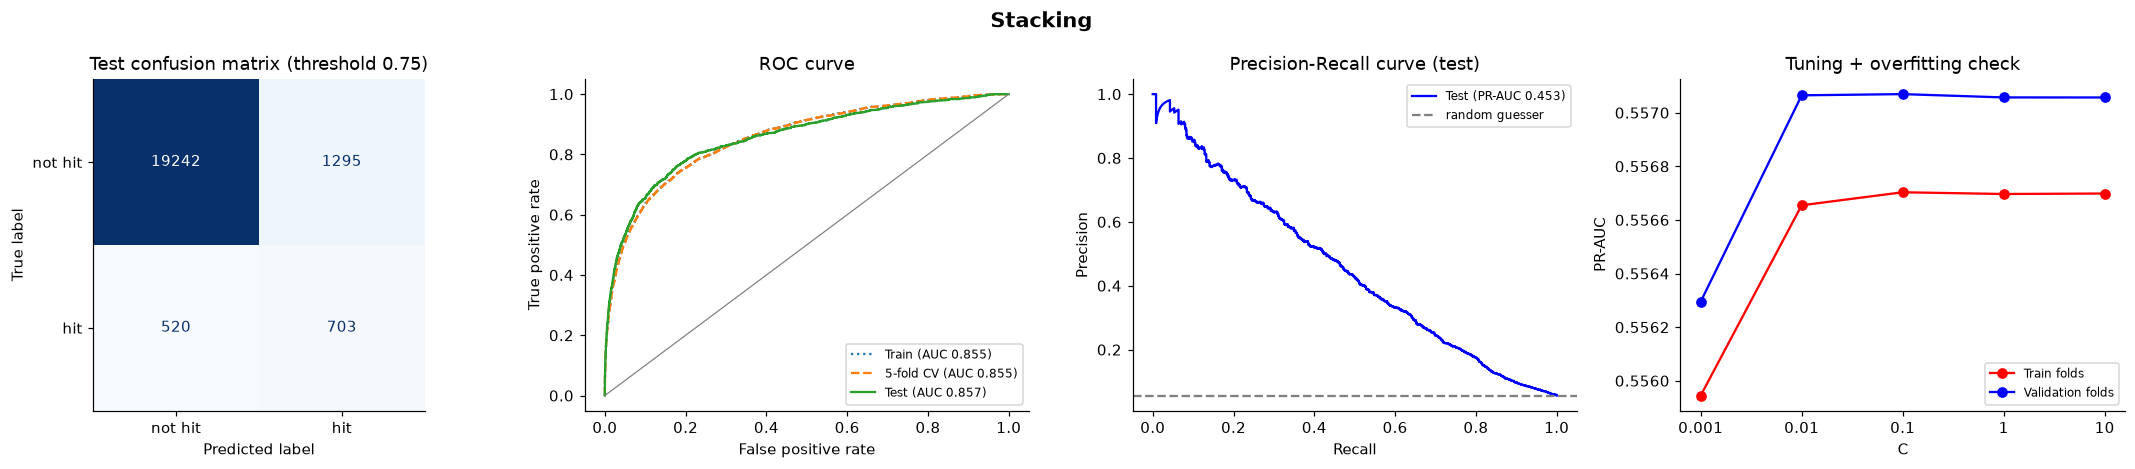

In [9]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
logreg_oof = cross_val_predict(logreg, X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
logreg.fit(X_train, y_train)

#log-odds of each base model's probability = the new features
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

BASE = ["Random Forest", "AdaBoost", "Gradient Boosting", "Logistic Regression"]
Z_train = pd.DataFrame(np.column_stack([logit(p) for p in [rf_oof, ada_oof, gb_oof, logreg_oof]]), columns=BASE)
Z_test = pd.DataFrame(np.column_stack([logit(m.predict_proba(X_test)[:, 1]) for m in [rf_best, ada_best, gb_best, logreg]]), columns=BASE)
print("How similar are the base models' predictions? (correlation)")
display(Z_train.corr(method="spearman").round(3))

stack_grid = GridSearchCV(LogisticRegression(class_weight="balanced", max_iter=2000),
                          {"C": [0.001, 0.01, 0.1, 1, 10]},
                          scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
stack_grid.fit(Z_train, y_train)
stack_best, _, _ = model_slide("Stacking", stack_grid, "C", Xtr=Z_train, Xte=Z_test)

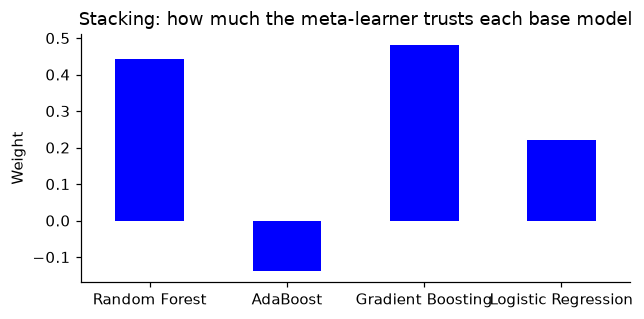

In [10]:
w = pd.Series(stack_best.coef_[0], index=BASE)
fig, ax = plt.subplots(figsize=(6, 3))
w.plot.bar(ax=ax, color="blue", rot=0)
ax.set_title("Stacking: how much the meta-learner trusts each base model")
ax.set_ylabel("Weight")
plt.tight_layout()
plt.show()

## Comparing the models
All test scores use each model's CV-picked threshold

In [11]:
comparison = pd.DataFrame({k: {c: v for c, v in r.items() if c != "p_test"} for k, r in results.items()}).T.astype(float)
comparison = comparison[["accuracy", "precision", "recall", "F1", "PR-AUC", "ROC-AUC", "CV PR-AUC", "train-CV gap", "threshold"]]
comparison = comparison.sort_values("PR-AUC", ascending=False)
print(f"Random guesser: Test PR-AUC {y_test.mean():.3f}     F1 {2 * y_test.mean() / (1 + y_test.mean()):.3f}")
print("Best by test PR-AUC:", comparison["PR-AUC"].idxmax(), "     Best by test F1:", comparison["F1"].idxmax())
comparison.round(3)

Random guesser: Test PR-AUC 0.056     F1 0.106
Best by test PR-AUC: Stacking      Best by test F1: Stacking


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC,CV PR-AUC,train-CV gap,threshold
Stacking,0.917,0.352,0.575,0.437,0.453,0.857,0.556,0.000,0.755
Random Forest,0.912,0.339,0.590,0.431,0.437,0.852,0.545,0.208,0.659
AdaBoost,0.903,0.313,0.609,0.414,0.437,0.854,0.544,0.012,0.621
Gradient Boosting,0.910,0.332,0.588,0.425,0.435,0.855,0.555,0.028,0.736
Bagging,0.913,0.339,0.569,0.425,0.427,0.850,0.533,0.093,0.672


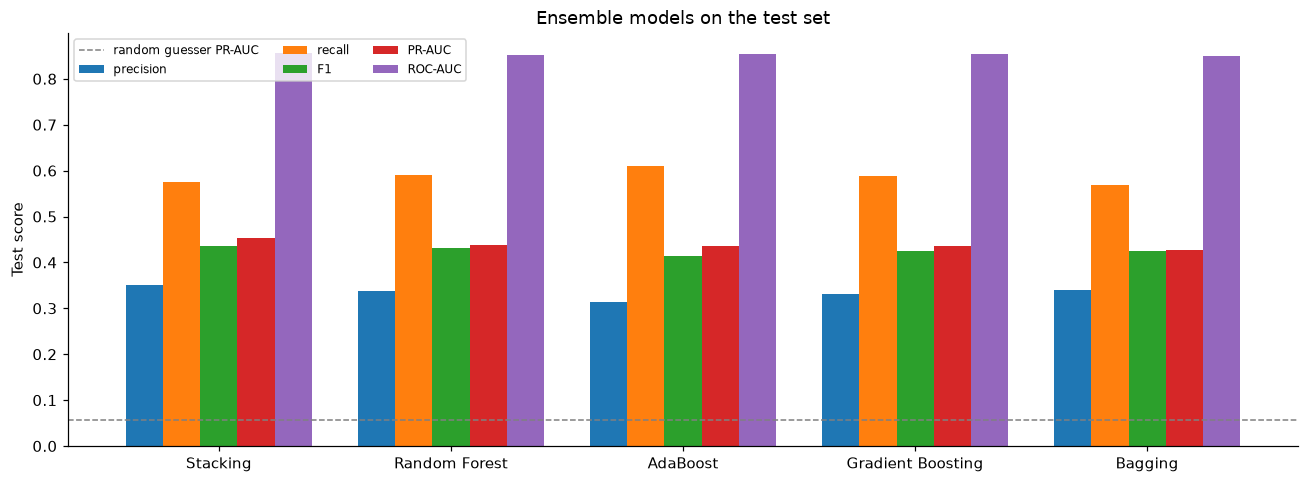

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.5))
comparison[["precision", "recall", "F1", "PR-AUC", "ROC-AUC"]].plot.bar(ax=ax, rot=0, width=0.8)
ax.axhline(y_test.mean(), color="gray", ls="--", lw=1, label="random guesser PR-AUC")
ax.set_ylabel("Test score")
ax.set_title("Ensemble models on the test set")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

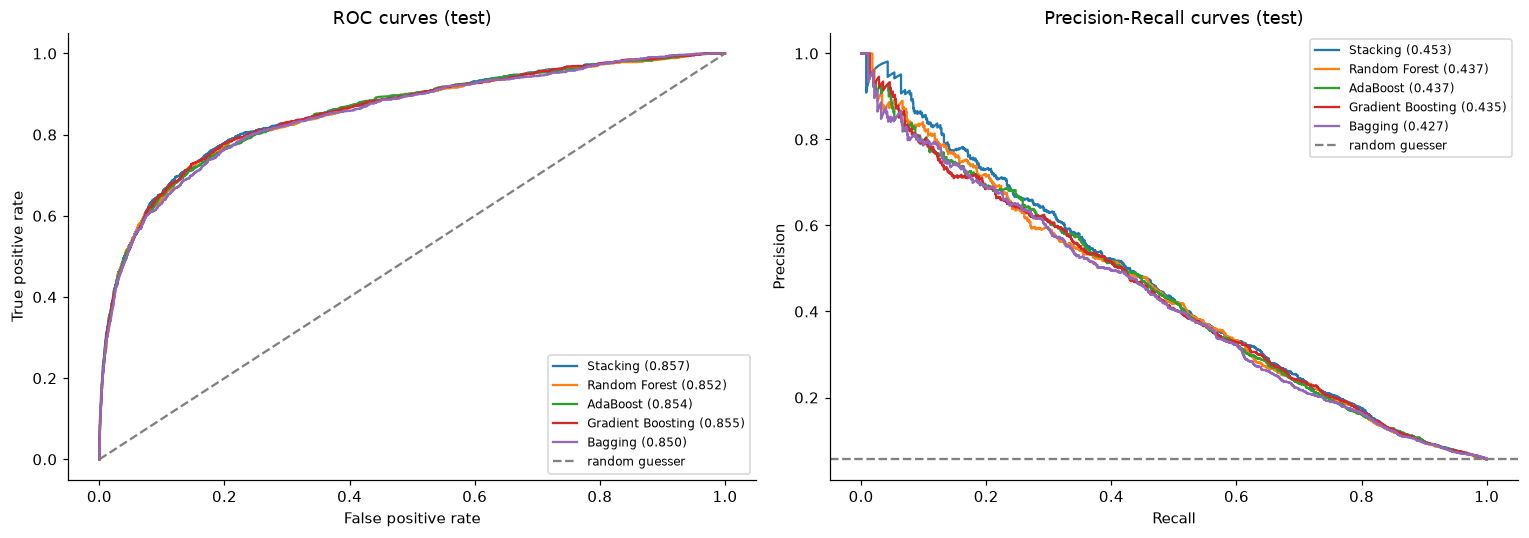

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in comparison.index:
    p = results[name]["p_test"]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", label="random guesser")
axes[1].axhline(y_test.mean(), color="gray", ls="--", label="random guesser")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves (test)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

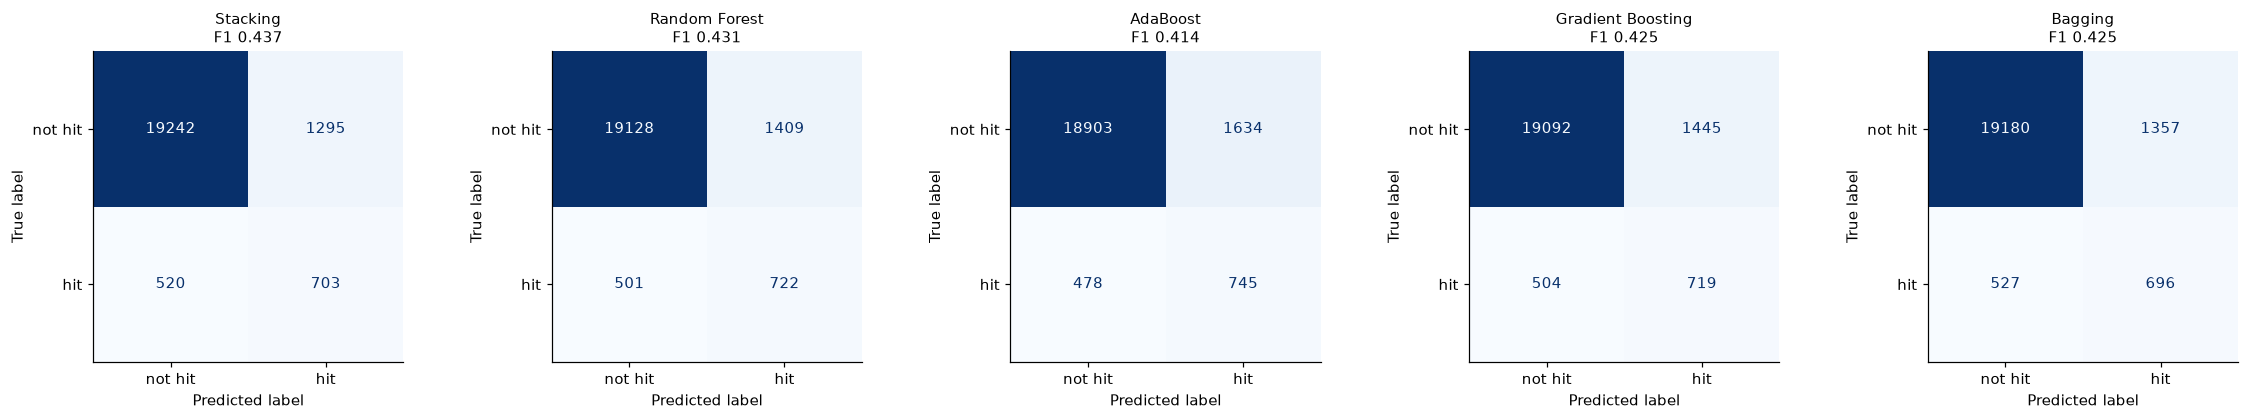

In [14]:
names = list(comparison.index)
fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 3.8))
for ax, name in zip(axes, names):
    thr = comparison.loc[name, "threshold"]
    ConfusionMatrixDisplay(confusion_matrix(y_test, (results[name]["p_test"] >= thr).astype(int)), display_labels=["not hit", "hit"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{name}\nF1 {comparison.loc[name, 'F1']:.3f}", fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()